In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
def load_dataset(file_path, target_column):
  df = pd.read_csv(file_path)
  X = df.drop(columns=[target_column])
  y = df[target_column]
  X_train, X_test, y_train, y_test = train_test_split(
      X, y, test_size=0.2, random_state=42
  )
  return X_train, X_test, y_train, y_test

In [3]:
def preprocess_data(X_train, X_test):
  train_df = X_train.copy()
  test_df = X_test.copy()

  numerical_cols = train_df.select_dtypes(include=[np.number]).columns
  categorical_cols = train_df.select_dtypes(exclude=[np.number]).columns

  # Fill missing values using the training data only
  for col in numerical_cols:
    mean = train_df[col].mean()
    train_df[col] = train_df[col].fillna(mean)
    test_df[col] = test_df[col].fillna(mean)

  for col in categorical_cols:
    mode = train_df[col].mode()[0]
    train_df[col] = train_df[col].fillna(mode)
    test_df[col] = test_df[col].fillna(mode)

  # One-hot encode the categorical columns
  train_df = pd.get_dummies(train_df, columns=categorical_cols, dtype=int)
  test_df = pd.get_dummies(test_df, columns=categorical_cols, dtype=int)
  test_df = test_df.reindex(columns=train_df.columns, fill_value=0)

  # Remove outliers from the training data (IQR method)
  for col in numerical_cols:
    Q1 = train_df[col].quantile(0.25)
    Q3 = train_df[col].quantile(0.75)
    IQR = Q3 - Q1
    train_df = train_df[
        (train_df[col] >= Q1 - 1.5 * IQR) & (train_df[col] <= Q3 + 1.5 * IQR)
    ]

  # Standardize the numerical columns
  train_df = train_df.copy()
  scaler = StandardScaler()
  train_df[numerical_cols] = scaler.fit_transform(train_df[numerical_cols])
  test_df[numerical_cols] = scaler.transform(test_df[numerical_cols])

  return train_df, test_df

In [4]:
def plot_correlation_map(train_df, y_train, target_column):
  combined_df = train_df.copy()
  combined_df[target_column] = y_train
  corr_matrix = combined_df.corr()
  print(corr_matrix[target_column].sort_values(ascending=False))
  plt.figure(figsize=(10, 8))
  sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
  plt.title("Correlation Heatmap")
  plt.tight_layout()
  plt.show()

In [5]:
def print_scores(name, y_test, y_pred, y_scaler):
  rmse = np.sqrt(mean_squared_error(y_test, y_pred))
  mae = mean_absolute_error(y_test, y_pred)
  r2 = r2_score(y_test, y_pred)
  print(f"\n=== {name} ===")
  print(f"RMSE: {rmse:.2f}")
  print(f"MAE (normalized): {mae:.2f}")
  print(f"MAE (original): {mae * y_scaler.scale_[0]:.2f}")
  print(f"R2: {r2:.4f}")

In [6]:
def train_linear_regression(X_train, X_test, y_train, y_test, y_scaler):
  model = LinearRegression()
  model.fit(X_train, y_train)
  y_pred = model.predict(X_test)
  print_scores("OLS", y_test, y_pred, y_scaler)
  return y_pred

In [7]:
def train_grid_search(name, model, X_train, X_test, y_train, y_test, y_scaler):
  param_grid = {"alpha": np.logspace(-4, 1, 20)}
  grid = GridSearchCV(
      model, param_grid, cv=5, scoring="neg_root_mean_squared_error"
  )
  grid.fit(X_train, y_train)
  y_pred = grid.predict(X_test)
  print_scores(name, y_test, y_pred, y_scaler)
  print(f"Best alpha: {grid.best_params_['alpha']:.4f}")
  return y_pred

In [8]:
def plot_predictions_and_residuals(y_test, all_predictions, y_scaler):
  y_actual = y_scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()
  fig, axes = plt.subplots(2, 3, figsize=(18, 10))

  for i, name in enumerate(all_predictions):
    y_pred = y_scaler.inverse_transform(
        all_predictions[name].reshape(-1, 1)
    ).ravel()
    residuals = y_actual - y_pred

    # Top row: predicted vs actual
    axes[0, i].scatter(y_actual, y_pred, alpha=0.3, s=10)
    axes[0, i].plot(
        [y_actual.min(), y_actual.max()],
        [y_actual.min(), y_actual.max()],
        color="red",
        linestyle="--",
    )
    axes[0, i].set_title(f"{name}: Predicted vs Actual")
    axes[0, i].set_xlabel("Actual")
    axes[0, i].set_ylabel("Predicted")

    # Bottom row: residual distribution
    sns.histplot(residuals, kde=True, bins=50, ax=axes[1, i])
    axes[1, i].set_title(f"{name}: Residual Distribution")
    axes[1, i].set_xlabel("Residual (actual - predicted)")

  plt.tight_layout()
  plt.show()

median_house_value            1.000000
median_income                 0.641293
ocean_proximity_<1H OCEAN     0.267390
total_rooms                   0.189854
ocean_proximity_NEAR BAY      0.162387
ocean_proximity_NEAR OCEAN    0.138812
housing_median_age            0.129534
households                    0.104969
total_bedrooms                0.081416
ocean_proximity_ISLAND        0.025911
longitude                    -0.031846
population                   -0.051366
latitude                     -0.161684
ocean_proximity_INLAND       -0.492171
Name: median_house_value, dtype: float64


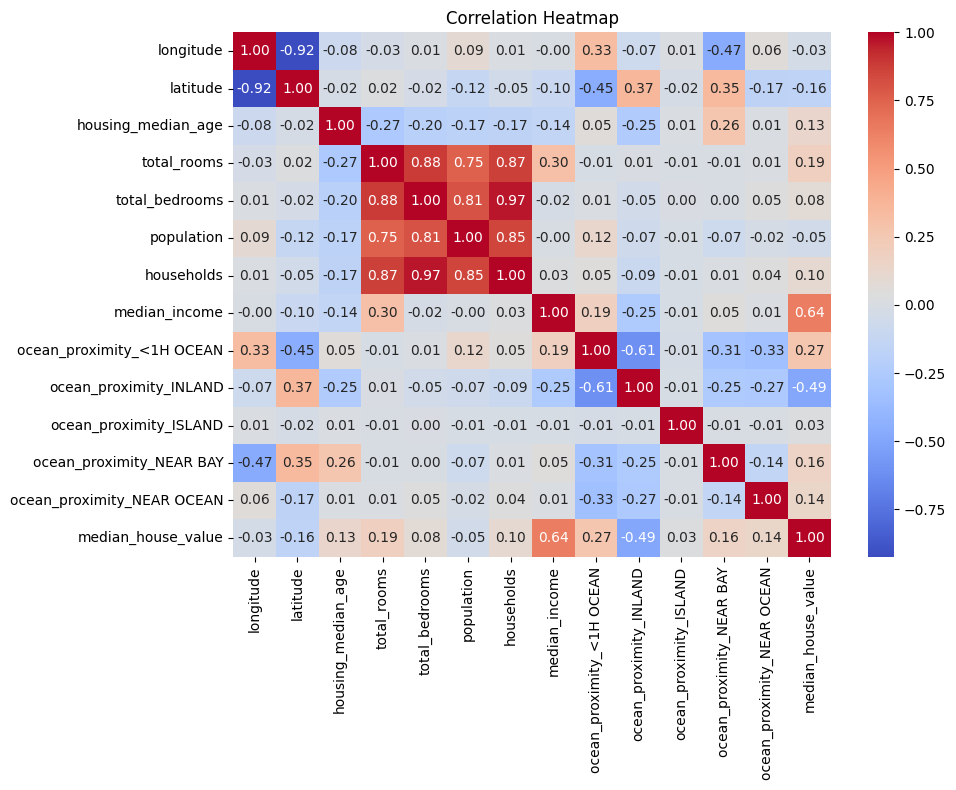

In [9]:
file_path = "realEstate.csv"
target_column = "median_house_value"

X_train, X_test, y_train, y_test = load_dataset(file_path, target_column)
X_train_processed, X_test_processed = preprocess_data(X_train, X_test)
y_train = y_train.loc[X_train_processed.index]
plot_correlation_map(X_train_processed, y_train, target_column)

In [10]:
# Normalize the target
y_scaler = StandardScaler()
y_train = y_scaler.fit_transform(y_train.values.reshape(-1, 1)).ravel()
y_test = y_scaler.transform(y_test.values.reshape(-1, 1)).ravel()

ols_pred = train_linear_regression(
    X_train_processed, X_test_processed, y_train, y_test, y_scaler
)
ridge_pred = train_grid_search(
    "Ridge (L2)", Ridge(), X_train_processed, X_test_processed,
    y_train, y_test, y_scaler,
)
lasso_pred = train_grid_search(
    "Lasso (L1)", Lasso(max_iter=10000), X_train_processed, X_test_processed,
    y_train, y_test, y_scaler,
)


=== OLS ===
RMSE: 0.72
MAE (normalized): 0.50
MAE (original): 54517.00
R2: 0.5413

=== Ridge (L2) ===
RMSE: 0.72
MAE (normalized): 0.50
MAE (original): 54519.19
R2: 0.5413
Best alpha: 0.8859

=== Lasso (L1) ===
RMSE: 0.72
MAE (normalized): 0.50
MAE (original): 54509.09
R2: 0.5415
Best alpha: 0.0001


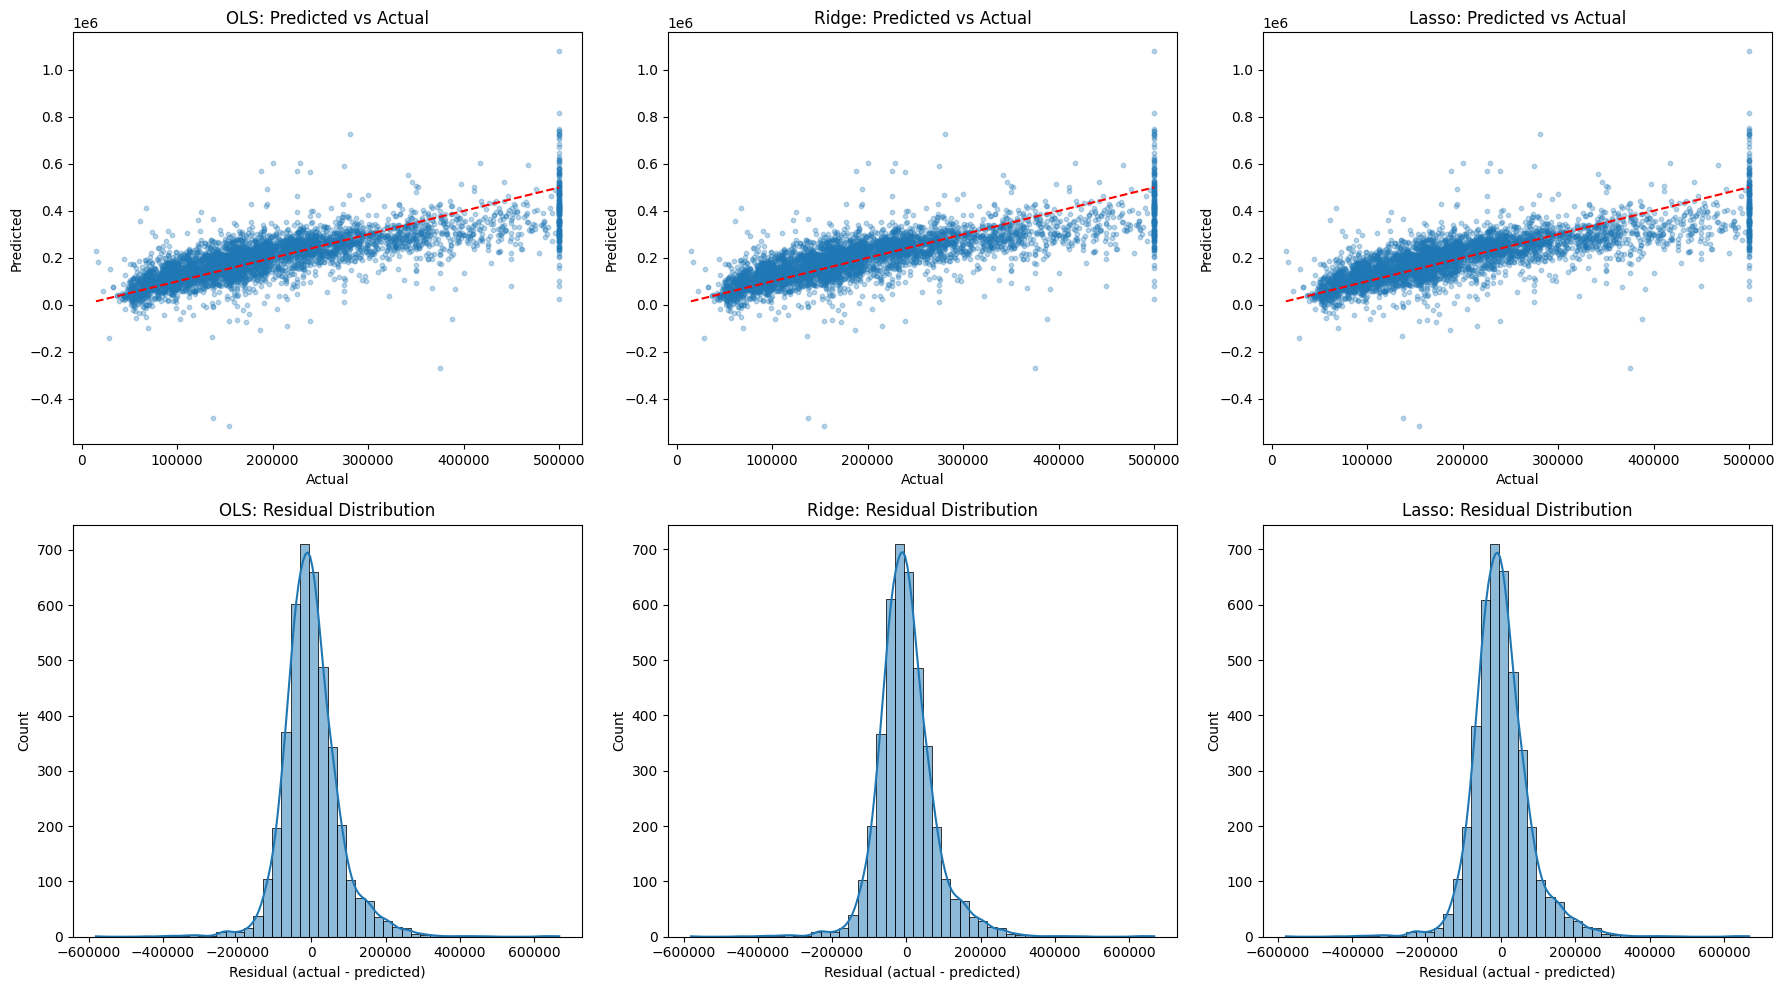

In [11]:
all_predictions = {"OLS": ols_pred, "Ridge": ridge_pred, "Lasso": lasso_pred}
plot_predictions_and_residuals(y_test, all_predictions, y_scaler)